In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries loaded ✅")

All libraries loaded ✅


In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
print("Raw dataset shape:", df.shape)
df.isnull().sum()

Raw dataset shape: (891, 12)


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [3]:
# Fill missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop column with too much missing data + remove duplicates
df = df.drop(columns=['Cabin'])
df = df.drop_duplicates()

df.to_csv('titanic_cleaned.csv', index=False)
print("Cleaned dataset:", df.shape, "— saved as titanic_cleaned.csv ✅")

Cleaned dataset: (891, 11) — saved as titanic_cleaned.csv ✅


Overall survival rate: 38.4 %


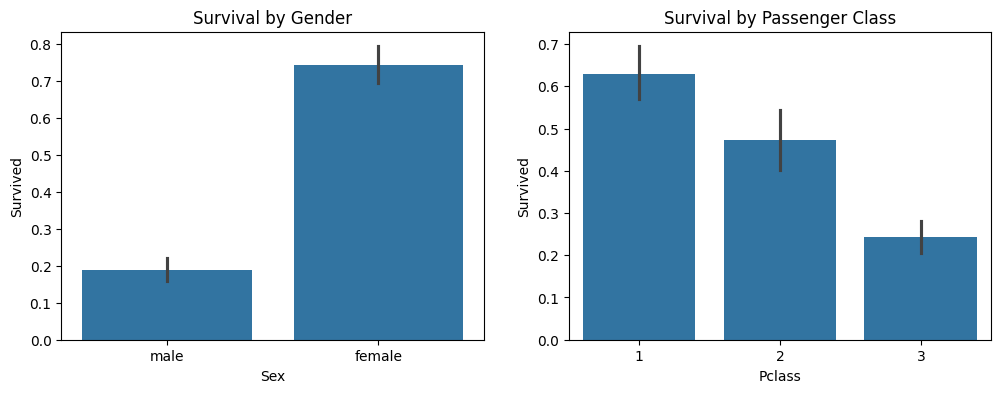

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


In [4]:
print("Overall survival rate:", round(df['Survived'].mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0])
axes[0].set_title('Survival by Gender')
sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival by Passenger Class')
plt.show()

print(df.groupby('Sex')['Survived'].mean() * 100)
print(df.groupby('Pclass')['Survived'].mean() * 100)

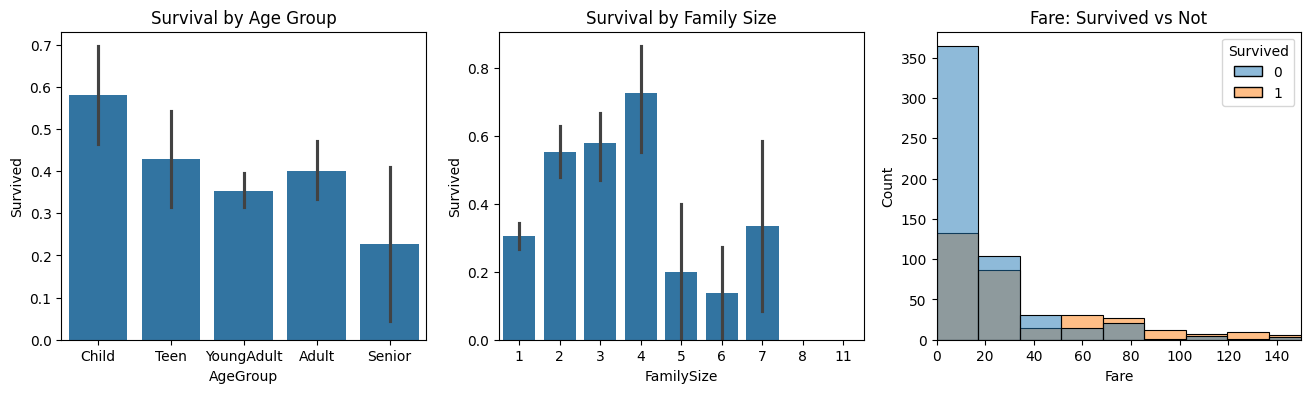

Avg fare — Survived: 48.4
Avg fare — Not Survived: 22.12


In [5]:
# Age groups
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 100],
                        labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'])

# Family size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x='AgeGroup', y='Survived', data=df, ax=axes[0])
axes[0].set_title('Survival by Age Group')
sns.barplot(x='FamilySize', y='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival by Family Size')
sns.histplot(data=df, x='Fare', hue='Survived', bins=30, ax=axes[2])
axes[2].set_title('Fare: Survived vs Not')
axes[2].set_xlim(0, 150)
plt.show()

print("Avg fare — Survived:", round(df[df['Survived']==1]['Fare'].mean(), 2))
print("Avg fare — Not Survived:", round(df[df['Survived']==0]['Fare'].mean(), 2))

In [6]:
# Convert text to numbers (models only understand numbers)
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
X = df[features]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training:", X_train.shape[0], "| Testing:", X_test.shape[0])

Training: 712 | Testing: 179


In [7]:
# Train baseline model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = model.predict(X_test)

print(f"🎯 Accuracy: {accuracy_score(y_test, y_pred) * 100:.1f}%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Died', 'Survived']))

🎯 Accuracy: 81.0%

Confusion Matrix:
[[90 15]
 [19 55]]

Classification Report:
              precision    recall  f1-score   support

        Died       0.83      0.86      0.84       105
    Survived       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



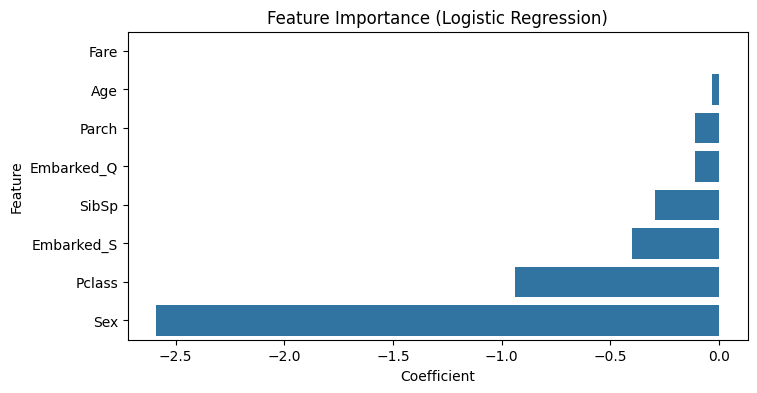

Logistic Regression: 81.0%
Random Forest:       81.0%


In [8]:
# Which features mattered most?
coefs = pd.DataFrame({'Feature': features, 'Coefficient': model.coef_[0]}
                    ).sort_values('Coefficient', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x='Coefficient', y='Feature', data=coefs)
plt.title('Feature Importance (Logistic Regression)')
plt.show()

# Compare with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print(f"Logistic Regression: {accuracy_score(y_test, y_pred) * 100:.1f}%")
print(f"Random Forest:       {accuracy_score(y_test, rf.predict(X_test)) * 100:.1f}%")